# MMIP Week 05 — Quiz 3：CLIP Image Captioning

本作業以 **Flickr8k** 作為影像描述資料集，使用預訓練 **CLIP ViT-B/32** 作為 Image Encoder，搭配 **GPT-2** 文字 Decoder 建立 Image Captioning 模型。

## 作業要求對照

| 要求 | 本 notebook 對應內容 |
|---|---|
| 資料準備（5 分） | Flickr8k 載入、切分、影像與文字前處理 |
| CLIP Encoder + 文字 Decoder（10 分） | `CLIPVisionModel` + `GPT2LMHeadModel` + cross-attention |
| 訓練與描述生成（5 分） | teacher forcing 訓練、beam search 推論、範例圖 |
| 與 Week 4 比較（10 分） | BLEU-1、BLEU-4、BERTScore F1 與比較表 |


## 1. 實驗環境

本實驗使用 PyTorch、Hugging Face Transformers／Datasets、NLTK 與 BERTScore，並固定主要套件版本範圍以維持可重現性。


In [1]:
%pip -q install -U "transformers>=4.45,<5" "datasets>=3,<5" "accelerate>=1,<2" "bert-score>=0.3.13" "nltk>=3.9" pandas matplotlib tqdm


## 2. 實驗設定與可重現性

- 訓練集 2,000 張、測試集 200 張、seed=42、訓練 3 epochs。
- CLIP Image Encoder 保持凍結，訓練 GPT-2 Decoder 與新加入的 cross-attention。
- 使用 beam search（beam size=5）產生影像描述。


In [2]:
import os, json, random, time
from pathlib import Path
from statistics import mean

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from transformers import (
    CLIPImageProcessor, CLIPVisionModel,
    GPT2Config, GPT2LMHeadModel, GPT2TokenizerFast,
    VisionEncoderDecoderModel, get_linear_schedule_with_warmup,
)

SEED = 42
TRAIN_SIZE = 2000
TEST_SIZE = 200
EPOCHS = 3
BATCH_SIZE = 4
LEARNING_RATE = 5e-5
MAX_LENGTH = 35
NUM_BEAMS = 5
ENCODER_NAME = "openai/clip-vit-base-patch32"
DECODER_NAME = "gpt2"
OUTPUT_DIR = Path("week05_clip_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print({"device": str(device), "train_size": TRAIN_SIZE, "test_size": TEST_SIZE,
       "epochs": EPOCHS, "torch": torch.__version__})


{'device': 'cuda', 'train_size': 2000, 'test_size': 200, 'epochs': 3, 'torch': '2.11.0+cu130'}


## 3. Flickr8k 資料準備

使用 Hugging Face Hub 上的 `jxie/flickr8k` 公開資料。資料中的每張影像包含多句人工描述；為了與 HW4 程式的評估定義完全一致，本次訓練與評估皆使用 `caption_0` 作為主要 reference。切分前固定 shuffle seed，避免 train/test 重疊並確保可重現。


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/687 [00:00<?, ?B/s]

data/train-00000-of-00002-2f8f6bfa852eac(…):   0%|          | 0.00/414M [00:00<?, ?B/s]

data/train-00001-of-00002-2173151d8cd6c7(…):   0%|          | 0.00/414M [00:00<?, ?B/s]

data/validation-00000-of-00001-7025a2b59(…):   0%|          | 0.00/138M [00:00<?, ?B/s]

data/test-00000-of-00001-42a2661d12c73e4(…):   0%|          | 0.00/137M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/6000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

欄位： ['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4']
train=2000, test=200, caption columns=['caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4']


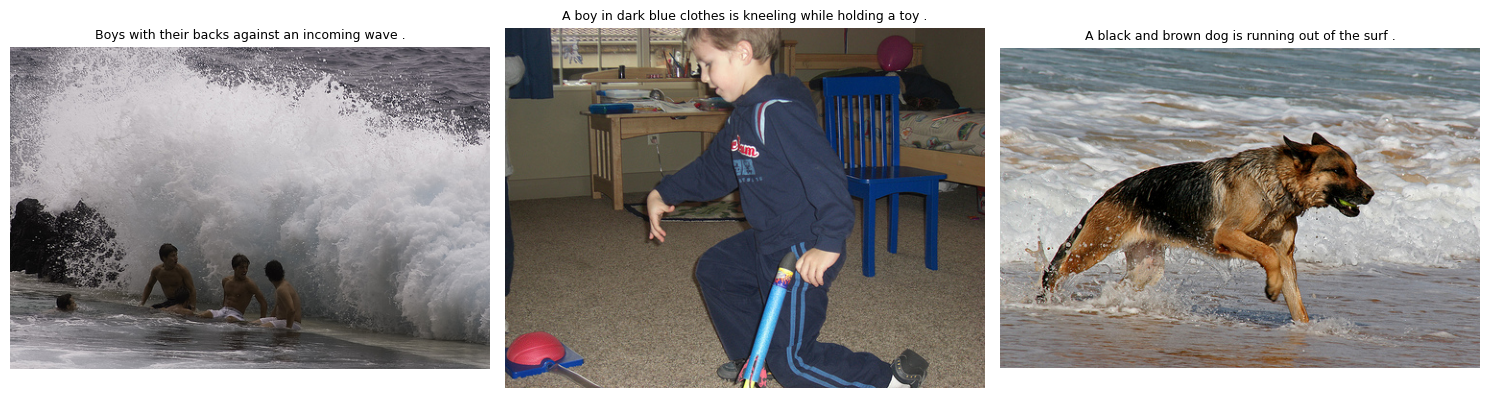

In [3]:
raw = load_dataset("jxie/flickr8k", split="train").shuffle(seed=SEED)
assert len(raw) >= TRAIN_SIZE + TEST_SIZE, "資料筆數不足，請降低 TRAIN_SIZE/TEST_SIZE"
train_ds = raw.select(range(TRAIN_SIZE))
test_ds = raw.select(range(TRAIN_SIZE, TRAIN_SIZE + TEST_SIZE))

caption_columns = [c for c in raw.column_names if c.startswith("caption_")]
print("欄位：", raw.column_names)
print(f"train={len(train_ds)}, test={len(test_ds)}, caption columns={caption_columns}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, row in zip(axes, train_ds.select(range(3))):
    ax.imshow(row["image"]); ax.axis("off"); ax.set_title(row["caption_0"], fontsize=9)
plt.tight_layout(); plt.show()


## 4. 建立 CLIP Encoder + GPT-2 Decoder

CLIP 將影像切成 patches，輸出視覺 hidden states。GPT-2 設為 decoder 並加入 cross-attention，使每一步文字生成都能關注 CLIP 的影像特徵。這不是直接使用完整的 BLIP，而是明確以 CLIP 作為 Image Encoder，符合本週題目。


In [4]:
image_processor = CLIPImageProcessor.from_pretrained(ENCODER_NAME)
tokenizer = GPT2TokenizerFast.from_pretrained(DECODER_NAME)
tokenizer.pad_token = tokenizer.eos_token

encoder = CLIPVisionModel.from_pretrained(ENCODER_NAME)
decoder_config = GPT2Config.from_pretrained(DECODER_NAME)
decoder_config.is_decoder = True
decoder_config.add_cross_attention = True
decoder = GPT2LMHeadModel.from_pretrained(DECODER_NAME, config=decoder_config)
model = VisionEncoderDecoderModel(encoder=encoder, decoder=decoder)

model.config.decoder_start_token_id = tokenizer.bos_token_id
model.config.eos_token_id = tokenizer.eos_token_id
model.config.pad_token_id = tokenizer.pad_token_id
model.config.vocab_size = model.config.decoder.vocab_size
model.generation_config.decoder_start_token_id = tokenizer.bos_token_id
model.generation_config.eos_token_id = tokenizer.eos_token_id
model.generation_config.pad_token_id = tokenizer.pad_token_id
model.generation_config.max_length = MAX_LENGTH
model.generation_config.num_beams = NUM_BEAMS

# 凍結 CLIP：保留預訓練影像語意，只學習 Decoder 與 cross-attention。
for p in model.encoder.parameters(): p.requires_grad = False
model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"parameters: trainable={trainable:,} / total={total:,} ({100*trainable/total:.1f}%)")


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Some weights of GPT2LMHeadModel were not initialized from the model checkpoint at gpt2 and are newly initialized: ['transformer.h.0.crossattention.c_attn.bias', 'transformer.h.0.crossattention.c_attn.weight', 'transformer.h.0.crossattention.c_proj.bias', 'transformer.h.0.crossattention.c_proj.weight', 'transformer.h.0.crossattention.q_attn.bias', 'transformer.h.0.crossattention.q_attn.weight', 'transformer.h.0.ln_cross_attn.bias', 'transformer.h.0.ln_cross_attn.weight', 'transformer.h.1.crossattention.c_attn.bias', 'transformer.h.1.crossattention.c_attn.weight', 'transformer.h.1.crossattention.c_proj.bias', 'transformer.h.1.crossattention.c_proj.weight', 'transformer.h.1.crossattention.q_attn.bias', 'transformer.h.1.crossattention.q_attn.weight', 'transformer.h.1.ln_cross_attn.bias', 'transformer.h.1.ln_cross_attn.weight', 'transformer.h.10.crossattention.c_attn.bias', 'transformer.h.10.crossattention.c_attn.weight', 'transformer.h.10.crossattention.c_proj.bias', 'transformer.h.10.cros

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

parameters: trainable=152,806,656 / total=240,262,656 (63.6%)


## 5. DataLoader 與訓練

文字標籤中的 padding 會改為 `-100`，使 cross-entropy 忽略補齊位置。Decoder 使用 teacher forcing：訓練時以前一個正確 token 預測下一個 token。


In [5]:
def collate_fn(rows):
    images = [r["image"].convert("RGB") for r in rows]
    # GPT-2 tokenizer 不會自動附加 EOS；明確加入，讓 Decoder 學會停止生成。
    captions = [r["caption_0"] + tokenizer.eos_token for r in rows]
    pixel_values = image_processor(images=images, return_tensors="pt").pixel_values
    labels = tokenizer(captions, padding=True, truncation=True,
                       max_length=MAX_LENGTH, return_tensors="pt").input_ids
    labels[labels == tokenizer.pad_token_id] = -100
    return {"pixel_values": pixel_values, "labels": labels}

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=collate_fn, num_workers=0, pin_memory=torch.cuda.is_available())

optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                              lr=LEARNING_RATE, weight_decay=0.01)
total_steps = EPOCHS * len(train_loader)
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=max(1, int(0.1 * total_steps)), num_training_steps=total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

history = []
train_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    model.train(); model.encoder.eval()  # frozen encoder 保持 eval
    running = 0.0
    bar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}")
    for batch in bar:
        optimizer.zero_grad(set_to_none=True)
        pixel_values = batch["pixel_values"].to(device, non_blocking=True)
        labels = batch["labels"].to(device, non_blocking=True)
        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            loss = model(pixel_values=pixel_values, labels=labels).loss
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        running += loss.item(); bar.set_postfix(loss=f"{loss.item():.3f}")
    epoch_loss = running / len(train_loader)
    history.append({"epoch": epoch, "train_loss": epoch_loss})
    print(f"epoch={epoch}, mean_loss={epoch_loss:.4f}")

training_seconds = time.perf_counter() - train_start
pd.DataFrame(history).to_csv(OUTPUT_DIR / "training_history.csv", index=False)
print(f"Training finished in {training_seconds:.1f} seconds")


Epoch 1/3:   0%|          | 0/500 [00:00<?, ?it/s]

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.
/tmp/ipykernel_436/2006752656.py:36: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(optimizer); scaler.update(); scheduler.step()


epoch=1, mean_loss=5.2258


Epoch 2/3:   0%|          | 0/500 [00:00<?, ?it/s]

epoch=2, mean_loss=4.1136


Epoch 3/3:   0%|          | 0/500 [00:00<?, ?it/s]

epoch=3, mean_loss=3.7196
Training finished in 275.3 seconds


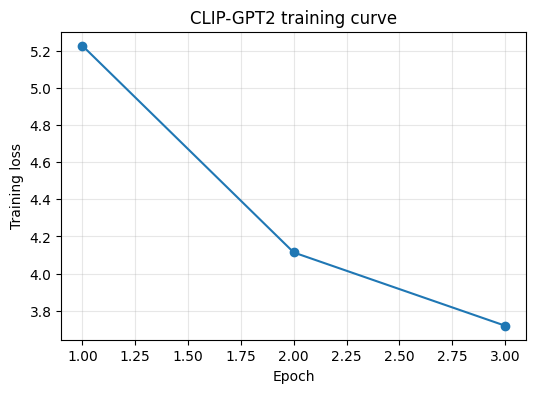

In [6]:
plt.figure(figsize=(6, 4))
plt.plot([x["epoch"] for x in history], [x["train_loss"] for x in history], marker="o")
plt.xlabel("Epoch"); plt.ylabel("Training loss"); plt.title("CLIP-GPT2 training curve"); plt.grid(alpha=.3)
plt.show()


## 6. Beam-search 推論

採用與 HW4 較佳結果相同的 beam size 5。逐張記錄 reference、prediction 與 latency，方便檢查錯誤案例並重算指標。


In [7]:
@torch.inference_mode()
def generate_caption(image):
    model.eval()
    pixel_values = image_processor(images=image.convert("RGB"), return_tensors="pt").pixel_values.to(device)
    if device.type == "cuda": torch.cuda.synchronize()
    start = time.perf_counter()
    ids = model.generate(pixel_values=pixel_values, max_length=MAX_LENGTH,
                         num_beams=NUM_BEAMS, early_stopping=True, no_repeat_ngram_size=2)
    if device.type == "cuda": torch.cuda.synchronize()
    latency = time.perf_counter() - start
    return tokenizer.decode(ids[0], skip_special_tokens=True).strip(), latency

records = []
for i, row in enumerate(tqdm(test_ds, desc="Captioning")):
    pred, latency = generate_caption(row["image"])
    records.append({"index": i, "reference": row["caption_0"],
                    "prediction": pred, "latency_seconds": latency})

predictions = pd.DataFrame(records)
predictions.to_csv(OUTPUT_DIR / "clip_gpt2_predictions.csv", index=False)
predictions.head(10)


Captioning:   0%|          | 0/200 [00:00<?, ?it/s]

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


,index,reference,prediction,latency_seconds
0,0,A skateboarder is jumping almost as high as a ...,man aboard a onboard the . . of . inair . a in...,1.078423
1,1,"A black and brown dog in a grassy , well-lit a...",black white and dog running the . a dog a ball...,0.527907
2,2,A man holds up an electronic device while he a...,man a and woman standing front a in of brick ....,0.508656
3,3,A group of men are playing rugby in a field wi...,man a player a plays a . in game another plays...,0.531194
4,4,A group of people are lounging at a beach .,man a in shorts on surfunks aboard the of . . ...,0.512044
5,5,A backpacker is walking in front of a mountain...,man aboard a onboard the . . of . in snow . th...,0.509630
6,6,A woman watching two kids playing at a pool .,man a in shorts aboard a boat the . . in . wat...,0.512662
7,7,A man sitting cross-legged in a field,man a wearing helmet a helmet walking the . . ...,0.520325
8,8,a dog playing ouside,black white and dog running a path a dog a . ....,0.514358
9,9,A black dog catches a tennis ball in his mouth...,black white and dog running the . a in grass f...,0.516943


## 7. BLEU 與 BERTScore

- **BLEU-1**：unigram 精確度，觀察主要物件／動作詞彙重合。
- **BLEU-4**：考慮最長四詞片段，更嚴格衡量句型與局部語序。
- **BERTScore F1**：以 contextual embedding 衡量語意相似性，較能容忍合理同義改寫。

為公平比較 Week 4，這裡沿用其「每張一個 `caption_0` reference、逐句 BLEU 後取平均」定義。


In [8]:
from nltk.translate.bleu_score import SmoothingFunction, sentence_bleu
from bert_score import score as bert_score

smooth = SmoothingFunction().method1
bleu1, bleu4 = [], []
for r in records:
    ref = r["reference"].lower().split()
    pred = r["prediction"].lower().split()
    bleu1.append(sentence_bleu([ref], pred, weights=(1, 0, 0, 0), smoothing_function=smooth))
    bleu4.append(sentence_bleu([ref], pred, smoothing_function=smooth))

_, _, bert_f1 = bert_score(
    predictions["prediction"].tolist(), predictions["reference"].tolist(),
    lang="en", batch_size=16, device=str(device), verbose=True)
predictions["bleu1"] = bleu1
predictions["bleu4"] = bleu4
predictions["bertscore_f1"] = bert_f1.cpu().numpy()
predictions.to_csv(OUTPUT_DIR / "clip_gpt2_predictions.csv", index=False)

clip_metrics = {
    "bleu1": float(predictions.bleu1.mean()),
    "bleu4": float(predictions.bleu4.mean()),
    "bertscore_f1": float(predictions.bertscore_f1.mean()),
    "latency_seconds": float(predictions.latency_seconds.mean()),
    "training_seconds": float(training_seconds),
}
clip_metrics


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

  0%|          | 0/25 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/13 [00:00<?, ?it/s]

done in 1.73 seconds, 115.39 sentences/sec


{'bleu1': 0.15978985760675996,
 'bleu4': 0.010557640398312317,
 'bertscore_f1': 0.814045250415802,
 'latency_seconds': 0.5442287962749981,
 'training_seconds': 275.25235477499996}

## 8. 與 Week 4 BLIP 比較

HW4 在相同 Flickr8k 規模（train=2,000、test=200、seed=42）的正式結果為：

- BLIP greedy：BLEU-1=0.2686、BLEU-4=0.0737、BERTScore F1=0.9119
- BLIP beam-5：BLEU-1=0.2890、BLEU-4=0.0831、BERTScore F1=0.9143

本次 CLIP-GPT2 同樣採用 beam-5，因此以 BLIP beam-5 作為主要比較基準。


In [9]:
week4 = {"bleu1": 0.28897918383834265, "bleu4": 0.08311712931644877,
         "bertscore_f1": 0.9143321663141251, "latency_seconds": 0.20536345800152048,
         "training_seconds": 177.3843068999704}

comparison = pd.DataFrame([
    {"model": "Week 4 BLIP (beam-5)", **week4},
    {"model": "Week 5 CLIP ViT-B/32 + GPT-2 (beam-5)", **clip_metrics},
])
for metric in ["bleu1", "bleu4", "bertscore_f1"]:
    comparison.loc[1, metric + "_vs_week4"] = comparison.loc[1, metric] - comparison.loc[0, metric]
comparison.to_csv(OUTPUT_DIR / "week4_week5_comparison.csv", index=False)
display(comparison.round(4))

with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump({"dataset": {"name": "Flickr8k", "train": TRAIN_SIZE, "test": TEST_SIZE,
                                "seed": SEED}, "clip_gpt2": clip_metrics,
               "week4_blip_beam5": week4}, f, ensure_ascii=False, indent=2)


,model,bleu1,bleu4,bertscore_f1,latency_seconds,training_seconds,bleu1_vs_week4,bleu4_vs_week4,bertscore_f1_vs_week4
0,Week 4 BLIP (beam-5),0.2890,0.0831,0.9143,0.2054,177.3843,NaN,NaN,NaN
1,Week 5 CLIP ViT-B/32 + GPT-2 (beam-5),0.1598,0.0106,0.8140,0.5442,275.2524,-0.1292,-0.0726,-0.1003


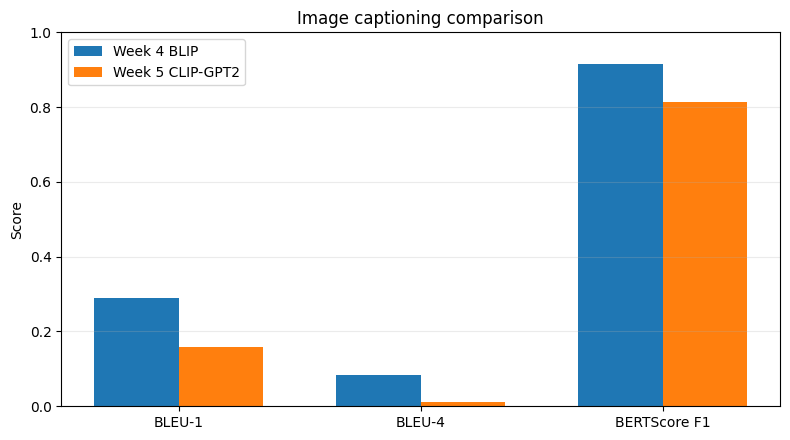

In [10]:
metric_names = ["bleu1", "bleu4", "bertscore_f1"]
x = np.arange(len(metric_names)); width = .35
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x-width/2, comparison.loc[0, metric_names], width, label="Week 4 BLIP")
ax.bar(x+width/2, comparison.loc[1, metric_names], width, label="Week 5 CLIP-GPT2")
ax.set_xticks(x, ["BLEU-1", "BLEU-4", "BERTScore F1"])
ax.set_ylim(0, 1); ax.set_ylabel("Score"); ax.set_title("Image captioning comparison")
ax.legend(); ax.grid(axis="y", alpha=.25); plt.tight_layout()
plt.savefig(OUTPUT_DIR / "metric_comparison.png", dpi=160); plt.show()


## 9. 視覺化推論結果與誤差分析

除了平均分數，需觀察模型是否抓到主體、動作、場景與物件關係。下列範例同時呈現人工 reference 與模型 prediction；可在報告中挑選成功與失敗案例討論。


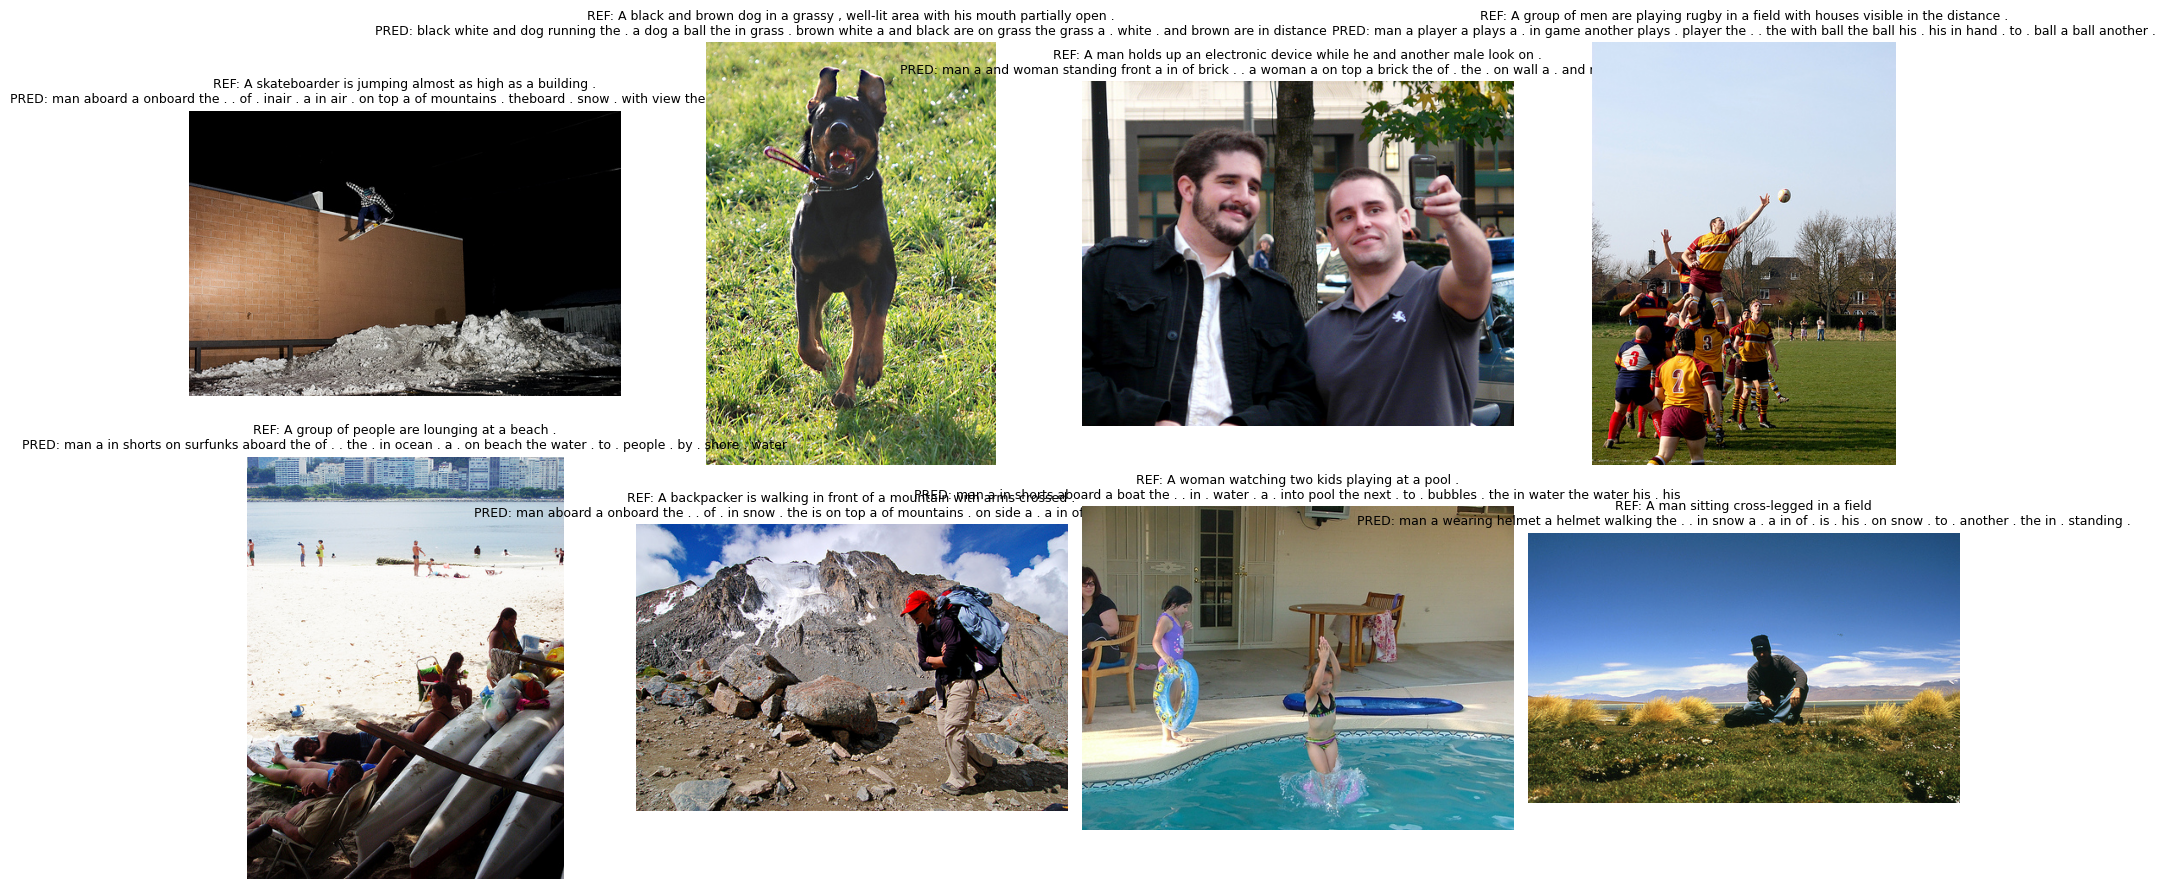

In [11]:
sample_ids = list(range(min(8, len(test_ds))))
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, idx in zip(axes.flat, sample_ids):
    row = test_ds[idx]; rec = records[idx]
    ax.imshow(row["image"]); ax.axis("off")
    ax.set_title(f"REF: {rec['reference']}\nPRED: {rec['prediction']}", fontsize=9)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "caption_examples.png", dpi=160); plt.show()


## 10. 實驗結論

本作業成功以 CLIP ViT-B/32 萃取影像特徵，並透過 cross-attention 將視覺 hidden states 傳給 GPT-2 Decoder，完成端到端訓練與影像描述生成。訓練 loss 從第 1 epoch 的 **5.2258** 降至第 3 epoch 的 **3.7196**，顯示模型確實持續學習。

CLIP-GPT2 beam-5 的 BLEU-1、BLEU-4 與 BERTScore F1 分別為 **0.1598、0.0106、0.8140**；相較 Week 4 BLIP beam-5 的 **0.2890、0.0831、0.9143**，分別下降 **0.1292、0.0726、0.1003**。CLIP-GPT2 的平均推論延遲為 **0.5442 秒／張**，高於 BLIP 的 **0.2054 秒／張**；訓練時間也較長（**275.25 秒 vs 177.38 秒**）。質化結果顯示模型已能捕捉部分常見主體與場景詞彙，但句子仍有重複、語序不自然及物件關係描述錯誤，因此 BLEU-4 特別低。

主要原因是 BLIP 已針對 image-text 任務進行跨模態預訓練；本模型則把原本分別預訓練的 CLIP 與 GPT-2 組合起來，新加入的 cross-attention 必須僅用 2,000 張影像從頭學習，而且 CLIP Encoder 保持凍結。結果說明「強影像 encoder＋強語言模型」不必然等同於良好的 image captioning 模型，跨模態對齊與生成式預訓練相當重要。後續可使用全部五句 captions、增加訓練資料與 epochs、分階段解凍 CLIP，或先進行 image-text alignment 預訓練，以改善描述品質。


## 11. 模型與實驗產出

儲存訓練後的 CLIP-GPT2 權重、tokenizer、影像處理器、逐筆預測、評估指標、比較表與視覺化結果，以利重現與後續分析。


In [12]:
MODEL_DIR = OUTPUT_DIR / "clip_gpt2_model"
model.save_pretrained(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)
image_processor.save_pretrained(MODEL_DIR)
print("Saved to", MODEL_DIR.resolve())


Saved to /content/week05_clip_outputs/clip_gpt2_model
